# Strategie-Vergleich: EWMA / Bollinger / GARCH Pairtrading

Laedt automatisch die je Basket besten, vom Quick-Tuner gefundenen
Parameter (`data/processed/tuning/best_params_<strategie>.json`, siehe
`quick_tune_ewma.py` / `quick_tune_bollinger.py` / `quick_tune_garch.py`),
fuehrt fuer jede Strategie und jeden getunten Basket EINEN finalen
Backtest auf dem Out-of-Sample-Testzeitraum durch (letzte `TEST_FRACTION`
des verfuegbaren Zeitraums, siehe `tuning_common.split_walkforward_test` --
derselbe Split, den die Quick-Tuner beim Tuning verwendet haben sollten)
und vergleicht die Ergebnisse visuell.

Kosten: `FEE_PRESET` (Standard: `"standard"` = 10.0 bps, Binance-Spot-
Taker-Satz, siehe `Src.config.BINANCE_FEE_PRESETS_BPS`) wird direkt aus
`tuning_common.resolve_fee_bps` uebernommen -- identische Kostenannahme
wie beim Tuning, keine getrennte Konstante hier im Notebook.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path(".").resolve()))
sys.path.insert(0, str(Path("../..").resolve()))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import pairtrading_engine as pte
import bollinger_pairtrading_engine as bpe
import garch_pairtrading_engine as ge
import tuning_common as tc

from Src.config import (
    ASSET_ID_COL, ASSETS_PATH, CLIQUES_DIR, CLOSE_COL,
    MARKET_SYMBOL_COL, OHLCV_DIR, TIMESTAMP_COL,
)
from Src.clustering.helpers import STABLECOIN_SYMBOLS

print("Imports OK")

Imports OK


## 1. Konfiguration

In [2]:
FEE_PRESET = "standard"        # siehe Src.config.BINANCE_FEE_PRESETS_BPS / tuning_common.resolve_fee_bps
FEE_BPS = tc.resolve_fee_bps(FEE_PRESET)
INITIAL_CAPITAL = tc.FIXED_INITIAL_CAPITAL
TEST_FRACTION = 0.2             # muss mit dem beim Quick-Tuning verwendeten Split uebereinstimmen
CLIQUES_VARIANT = "cliques_raw_12h"  # siehe data/processed/cliques/*.parquet

STRATEGIES = {
    "EWMA":      {"module": pte, "runner": "run_pairtrading_backtest", "strategy_key": "ewma"},
    "Bollinger": {"module": bpe, "runner": "run_bollinger_backtest",   "strategy_key": "bollinger"},
    "GARCH":     {"module": ge,  "runner": "run_garch_backtest",       "strategy_key": "garch"},
}

# Begrenzt den Testzeitraum auf die LETZTEN MAX_TEST_DAYS Tage des per
# TEST_FRACTION abgeleiteten Fensters (None = kompletter Testzeitraum, wie
# bisher). Macht die Backtests in Abschnitt 5 deutlich schneller -- vor
# allem GARCH (Fit pro Paar/Tag) profitiert stark von einem kuerzeren
# Fenster. Fuer eine schnelle Plausibilitaetspruefung reichen wenige Tage,
# fuer den finalen Vergleich sollte MAX_TEST_DAYS wieder auf None gesetzt
# werden (voller, unverkuerzter Out-of-Sample-Testzeitraum).
MAX_TEST_DAYS = 14

print(f"Fee-Preset: {FEE_PRESET} -> {FEE_BPS} bps | Startkapital: {INITIAL_CAPITAL:,.0f}")
print(f"MAX_TEST_DAYS: {MAX_TEST_DAYS if MAX_TEST_DAYS else 'kein Limit (voller Testzeitraum)'}")

Fee-Preset: standard -> 10.0 bps | Startkapital: 10,000
MAX_TEST_DAYS: 14


## 2. Daten laden (Cliquen + OHLCV + Asset-Symbole)

In [3]:
assets_df = pd.read_parquet(ASSETS_PATH)[["asset_id", "symbol"]].drop_duplicates()
id_to_symbol = dict(zip(assets_df["asset_id"], assets_df["symbol"]))
excluded_ids_stablecoins = set(
    assets_df.loc[assets_df["symbol"].isin(STABLECOIN_SYMBOLS), "asset_id"].tolist()
)

ohlcv_files = sorted(OHLCV_DIR.glob("*.parquet"))
raw = pd.concat([pd.read_parquet(f) for f in ohlcv_files], ignore_index=True)
raw["base_symbol"] = raw[MARKET_SYMBOL_COL].str.replace("USDT$", "", regex=True)
raw = raw.merge(assets_df.rename(columns={"symbol": "base_symbol"}), on="base_symbol", how="left")
raw = raw.dropna(subset=["asset_id"])
raw["asset_id"] = raw["asset_id"].astype(int)
raw[TIMESTAMP_COL] = pd.to_datetime(raw[TIMESTAMP_COL], utc=True)
raw = raw.loc[~raw["asset_id"].isin(excluded_ids_stablecoins)]
ohlcv_df = raw[[TIMESTAMP_COL, ASSET_ID_COL, CLOSE_COL]].copy()

cliques_df_full = pd.read_parquet(CLIQUES_DIR / f"{CLIQUES_VARIANT}.parquet")

data_min = ohlcv_df[TIMESTAMP_COL].min()
data_max = ohlcv_df[TIMESTAMP_COL].max()
print(f"Zeitraum: {data_min.date()} -> {data_max.date()}")
print(f"OHLCV: {ohlcv_df.shape[0]:,} Zeilen | Assets: {ohlcv_df[ASSET_ID_COL].nunique()}")
print(f"Baskets in '{CLIQUES_VARIANT}': {sorted(cliques_df_full['basket'].unique())}")

Zeitraum: 2024-07-23 -> 2026-07-22
OHLCV: 8,553,834 Zeilen | Assets: 45
Baskets in 'cliques_raw_12h': ['Basket 1', 'Basket 2', 'Basket 3', 'Basket 4']


## 3. Testzeitraum ableiten (identisch zum Quick-Tuning-Split)

In [4]:
_, _, test_start, test_end = tc.split_walkforward_test(data_min, data_max, test_fraction=TEST_FRACTION)

if MAX_TEST_DAYS is not None:
    # Nur die LETZTEN MAX_TEST_DAYS Tage des Testzeitraums verwenden -- der
    # Testzeitraum bleibt am selben Ende (test_end unveraendert), nur
    # test_start wird nach hinten verschoben. Kein Leakage: das Fenster
    # bleibt vollstaendig innerhalb des urspruenglich per TEST_FRACTION
    # abgeleiteten, waehrend des Tunings nie beruehrten Testzeitraums.
    shortened_start = test_end - pd.Timedelta(days=MAX_TEST_DAYS)
    test_start = max(test_start, shortened_start)

print(f"Out-of-Sample-Testzeitraum: {test_start.date()} -> {test_end.date()} "
      f"({(test_end - test_start).days} Tage)")

Out-of-Sample-Testzeitraum: 2026-07-08 -> 2026-07-22 (14 Tage)


## 4. Beste Parameter je Strategie/Basket laden

In [5]:
REQUIRED_PARAM_KEYS = {
    "EWMA": {"lookback_candles", "p_content", "trade_mode", "recalib_every",
             "max_holding_hours", "max_concurrent_positions", "ewma_decay", "exit_lookback_candles"},
    "Bollinger": {"lookback_candles", "n_std", "exit_lookback_candles", "trade_mode",
                  "max_holding_hours", "max_concurrent_positions", "hedge_lookback_candles"},
    "GARCH": {"lookback_candles", "p_content", "trade_mode", "recalib_every",
              "max_holding_hours", "max_concurrent_positions"},
}


def _missing_keys(strategy_name: str, params: dict) -> set:
    """Fehlende Pflicht-Parameter fuer strategy_name -- kann bei Eintraegen
    auftreten, die von einer AELTEREN quick_tune_*.py-Version stammen, bei
    der study.best_params nur die GESUCHTEN (nicht die fixierten) Parameter
    enthielt (siehe tuning_common-Historie). Wird VOR dem Backtest geprueft,
    damit die Meldung klar auf die Ursache zeigt statt eines rohen KeyError
    mitten im Backtest-Aufruf."""
    return REQUIRED_PARAM_KEYS[strategy_name] - set(params.keys())


best_params_by_strategy = {name: tc.load_best_params(cfg["strategy_key"]) for name, cfg in STRATEGIES.items()}

available_rows = []
for strat_name, by_basket in best_params_by_strategy.items():
    for basket, params in by_basket.items():
        missing = _missing_keys(strat_name, params)
        available_rows.append({
            "strategy": strat_name, "basket": basket,
            "objective": params.get("objective"), "n_trials": params.get("n_trials"),
            "tuned_at": params.get("tuned_at"),
            "vollstaendig": not missing,
            "fehlende_keys": ", ".join(sorted(missing)) if missing else "",
        })
available_df = pd.DataFrame(available_rows)

if available_df.empty:
    print(
        "Keine getunten Parameter gefunden. Vor diesem Notebook einen oder mehrere der "
        "Quick-Tuner laufen lassen:\n"
        "  quick_tune_ewma.tune_ewma_strategy(...)\n"
        "  quick_tune_bollinger.tune_bollinger_strategy(...)\n"
        "  quick_tune_garch.tune_garch_strategy(...)\n"
        "Jeder Aufruf speichert automatisch nach data/processed/tuning/best_params_<strategie>.json."
    )
else:
    display(available_df.sort_values(["basket", "strategy"]))
    n_incomplete = int((~available_df["vollstaendig"]).sum())
    if n_incomplete:
        print(
            f"\n{n_incomplete} Eintrag/Eintraege sind UNVOLLSTAENDIG (fehlende_keys-Spalte) -- "
            f"vermutlich von einer aelteren quick_tune_*.py-Version gespeichert. Diese werden in "
            f"Abschnitt 5 uebersprungen, mit klarer Meldung statt KeyError. Fix: den betroffenen "
            f"Basket in quick_tuning.ipynb erneut tunen (ueberschreibt den Eintrag vollstaendig)."
        )

,strategy,basket,objective,n_trials,tuned_at,vollstaendig,fehlende_keys
1,Bollinger,Basket 1,-0.073590,20,2026-08-13T16:55:46.642717+00:00,True,
0,EWMA,Basket 2,-0.029764,30,2026-08-13T16:17:56.715377+00:00,True,
2,GARCH,Basket 2,-0.065846,2,2026-08-13T16:08:44.113823+00:00,True,


## 5. Finalen Backtest je (Strategie, Basket) auf dem Testzeitraum ausfuehren

In [6]:
def _max_holding_candles(params: dict) -> int:
    return max(1, int(round(params["max_holding_hours"] * 60 / 5)))


def run_final_backtest(strategy_name: str, basket: str, params: dict) -> dict:
    """Fuehrt EINEN finalen Backtest fuer (strategy_name, basket) auf dem
    Out-of-Sample-Testzeitraum aus, mit den vom Quick-Tuner gefundenen besten
    Parametern. Gibt trades_df/equity_curve/stats zurueck (wie
    pairtrading_engine.compute_backtest_stats/compute_equity_curve --
    strategieuebergreifend identisch, siehe dortige Modul-Docstrings)."""
    cliques_df = cliques_df_full[cliques_df_full["basket"] == basket]
    max_holding_candles = _max_holding_candles(params)
    common_kwargs = dict(
        cliques_df=cliques_df, ohlcv_df=ohlcv_df, id_to_symbol=id_to_symbol,
        timestamp_column=TIMESTAMP_COL, asset_id_column=ASSET_ID_COL, close_column=CLOSE_COL,
        start_date=test_start, end_date=test_end - pd.Timedelta(days=1),
        max_holding_candles=max_holding_candles, fee_bps=FEE_BPS,
        trade_mode=params["trade_mode"],
    )

    if strategy_name == "EWMA":
        trades_df = pte.run_pairtrading_backtest(
            **common_kwargs,
            decay=params["ewma_decay"], lookback_candles=params["lookback_candles"],
            p_content=params["p_content"], confidence=tc.FIXED_CONFIDENCE,
            exit_lookback_candles=params["exit_lookback_candles"],
            recalib_every=params["recalib_every"],
        )
        max_concurrent = params["max_concurrent_positions"]
    elif strategy_name == "Bollinger":
        trades_df = bpe.run_bollinger_backtest(
            **common_kwargs,
            lookback_candles=params["lookback_candles"], n_std=params["n_std"],
            exit_lookback_candles=params["exit_lookback_candles"],
            hedge_lookback_candles=params["hedge_lookback_candles"],
        )
        max_concurrent = params["max_concurrent_positions"]
    elif strategy_name == "GARCH":
        trades_df = ge.run_garch_backtest(
            **common_kwargs,
            lookback_candles=params["lookback_candles"], p_content=params["p_content"],
            confidence=tc.FIXED_CONFIDENCE, recalib_every=params["recalib_every"],
        )
        max_concurrent = params["max_concurrent_positions"]
    else:
        raise ValueError(f"Unbekannte Strategie: {strategy_name}")

    equity_curve = pte.compute_equity_curve(
        trades_df, initial_capital=INITIAL_CAPITAL, max_concurrent_positions=max_concurrent,
    )
    stats = pte.compute_backtest_stats(trades_df, equity_curve)
    return {"trades_df": trades_df, "equity_curve": equity_curve, "stats": stats}


results: dict[tuple[str, str], dict] = {}
for strat_name, by_basket in best_params_by_strategy.items():
    for basket, params in by_basket.items():
        missing = _missing_keys(strat_name, params)
        if missing:
            print(f"Backtest: {strat_name} / {basket} ... UEBERSPRUNGEN "
                  f"(unvollstaendiger Eintrag, es fehlen: {sorted(missing)} -- "
                  f"in quick_tuning.ipynb neu tunen)")
            continue
        print(f"Backtest: {strat_name} / {basket} ...")
        try:
            results[(strat_name, basket)] = run_final_backtest(strat_name, basket, params)
        except Exception as exc:
            print(f"  FEHLER bei {strat_name}/{basket}: {exc}")

print(f"\n{len(results)} Backtests abgeschlossen.")

Backtest: EWMA / Basket 2 ...
Backtest: Bollinger / Basket 1 ...
Backtest: GARCH / Basket 2 ...

3 Backtests abgeschlossen.


## 6. Kennzahlen-Tabelle

In [7]:
stats_rows = []
for (strat_name, basket), res in results.items():
    stats_rows.append({"strategy": strat_name, "basket": basket, **res["stats"]})

if stats_rows:
    stats_df = pd.DataFrame(stats_rows).sort_values(["basket", "strategy"]).reset_index(drop=True)
    display(stats_df)
else:
    stats_df = pd.DataFrame(columns=["strategy", "basket"])
    print("Keine erfolgreichen Backtests -- siehe Fehlermeldungen in Abschnitt 5.")

,strategy,basket,n_trades,win_rate,avg_net_return,sharpe,max_drawdown,total_return,avg_holding_hours
0,Bollinger,Basket 1,252,0.071429,-0.004535,-42.626430,-0.297583,-0.297583,6.575397
1,EWMA,Basket 2,51,0.039216,-0.003525,-84.479281,-0.115554,-0.115554,2.601307
2,GARCH,Basket 2,74,0.013514,-0.003713,-1063.199654,-0.186707,-0.186555,0.092342


## 7. Plots

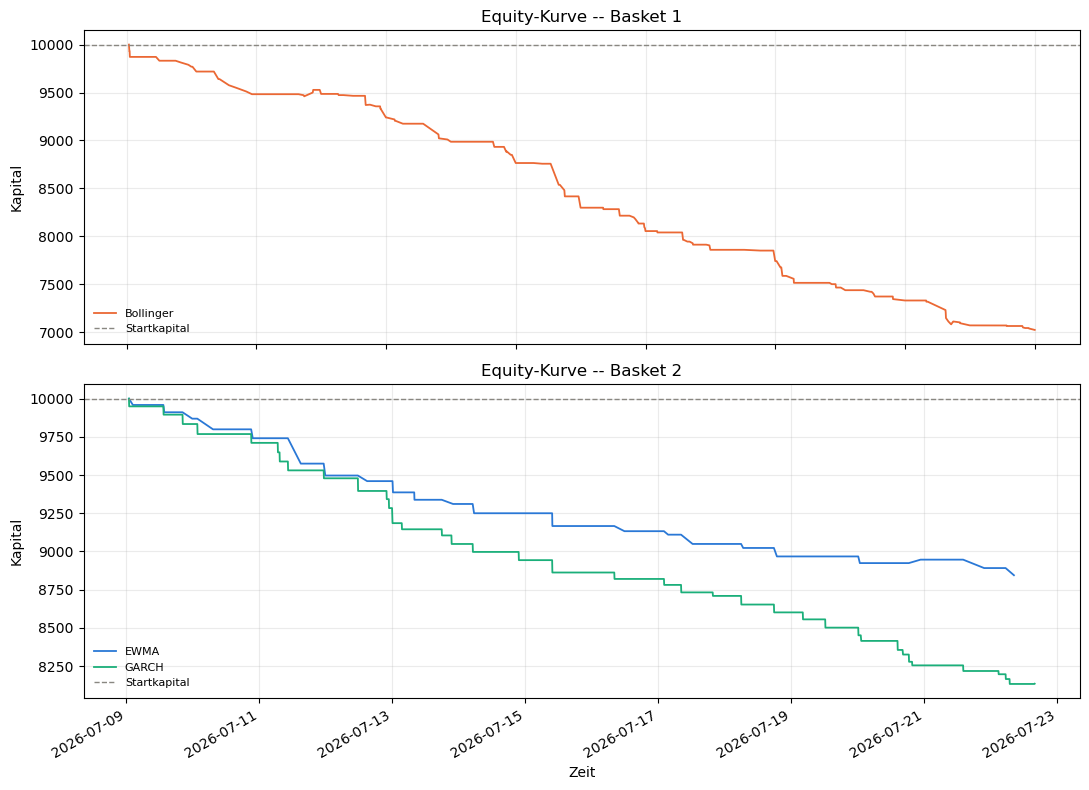

In [8]:
STRATEGY_COLORS = {"EWMA": "#2a78d6", "Bollinger": "#eb6834", "GARCH": "#1baf7a"}


def plot_equity_curves_by_basket(results: dict, *, show: bool = True):
    """Ein Subplot je Basket, darin je eine Equity-Kurve pro Strategie --
    direkter visueller Vergleich, wie stark sich die drei Signalarten auf
    denselben Cliquen unterscheiden."""
    baskets = sorted({b for _, b in results})
    fig, axes = plt.subplots(len(baskets), 1, figsize=(11, 4 * len(baskets)), squeeze=False)
    axes = axes[:, 0]

    for ax, basket in zip(axes, baskets):
        for strat_name in STRATEGIES:
            res = results.get((strat_name, basket))
            if res is None or res["equity_curve"].empty:
                continue
            curve = res["equity_curve"]
            ax.plot(curve.index, curve.values, color=STRATEGY_COLORS[strat_name],
                     linewidth=1.3, label=strat_name)
        ax.axhline(INITIAL_CAPITAL, color="#898781", linewidth=1, linestyle="--", label="Startkapital")
        ax.set_title(f"Equity-Kurve -- {basket}")
        ax.set_xlabel("Zeit")
        ax.set_ylabel("Kapital")
        ax.legend(frameon=False, fontsize=8)
        ax.grid(True, alpha=0.25)

    fig.autofmt_xdate()
    fig.tight_layout()
    if show:
        plt.show()
    return fig


def plot_metric_bars(stats_df: pd.DataFrame, metric: str, *, ylabel: str, show: bool = True):
    """Gruppierte Balken: x=Basket, Balkengruppe=Strategie, Hoehe=metric."""
    baskets = sorted(stats_df["basket"].unique())
    strat_names = list(STRATEGIES.keys())
    x = np.arange(len(baskets))
    width = 0.8 / len(strat_names)

    fig, ax = plt.subplots(figsize=(9, 4.5))
    for i, strat_name in enumerate(strat_names):
        values = []
        for basket in baskets:
            row = stats_df.loc[(stats_df["basket"] == basket) & (stats_df["strategy"] == strat_name), metric]
            values.append(row.iloc[0] if len(row) else np.nan)
        ax.bar(x + i * width, values, width=width, label=strat_name, color=STRATEGY_COLORS[strat_name])

    ax.axhline(0, color="#898781", linewidth=0.8)
    ax.set_xticks(x + width * (len(strat_names) - 1) / 2)
    ax.set_xticklabels(baskets, rotation=0)
    ax.set_ylabel(ylabel)
    ax.set_title(f"{ylabel} je Basket/Strategie")
    ax.legend(frameon=False)
    ax.grid(True, axis="y", alpha=0.25)
    fig.tight_layout()
    if show:
        plt.show()
    return fig


def plot_trade_return_distributions(results: dict, *, show: bool = True):
    """Ein Subplot je Basket: Histogramm der Trade-net_return-Verteilung je
    Strategie -- zeigt, ob eine Strategie viele kleine Gewinne/Verluste oder
    wenige grosse Ausreisser produziert."""
    baskets = sorted({b for _, b in results})
    fig, axes = plt.subplots(1, len(baskets), figsize=(6 * len(baskets), 4), squeeze=False)
    axes = axes[0]

    for ax, basket in zip(axes, baskets):
        for strat_name in STRATEGIES:
            res = results.get((strat_name, basket))
            if res is None or res["trades_df"].empty:
                continue
            ax.hist(res["trades_df"]["net_return"] * 100, bins=40, alpha=0.5,
                    color=STRATEGY_COLORS[strat_name], label=strat_name)
        ax.axvline(0, color="#898781", linewidth=0.8)
        ax.set_title(f"Trade-Renditen -- {basket}")
        ax.set_xlabel("Net Return (%)")
        ax.set_ylabel("Anzahl Trades")
        ax.legend(frameon=False, fontsize=8)
        ax.grid(True, alpha=0.25)

    fig.tight_layout()
    if show:
        plt.show()
    return fig


def plot_drawdown_curves(results: dict, *, show: bool = True):
    """Ein Subplot je Basket: laufender Drawdown (%) je Strategie ueber die
    Zeit -- ergaenzt die Equity-Kurve um die Risikosicht."""
    baskets = sorted({b for _, b in results})
    fig, axes = plt.subplots(len(baskets), 1, figsize=(11, 3.5 * len(baskets)), squeeze=False)
    axes = axes[:, 0]

    for ax, basket in zip(axes, baskets):
        for strat_name in STRATEGIES:
            res = results.get((strat_name, basket))
            if res is None or res["equity_curve"].empty:
                continue
            curve = res["equity_curve"]
            drawdown = (curve / curve.cummax() - 1.0) * 100
            ax.plot(drawdown.index, drawdown.values, color=STRATEGY_COLORS[strat_name],
                     linewidth=1.2, label=strat_name)
        ax.set_title(f"Drawdown -- {basket}")
        ax.set_xlabel("Zeit")
        ax.set_ylabel("Drawdown (%)")
        ax.legend(frameon=False, fontsize=8)
        ax.grid(True, alpha=0.25)

    fig.autofmt_xdate()
    fig.tight_layout()
    if show:
        plt.show()
    return fig


if results:
    plot_equity_curves_by_basket(results)
else:
    print("Keine Ergebnisse zum Plotten -- siehe Abschnitt 4/5.")

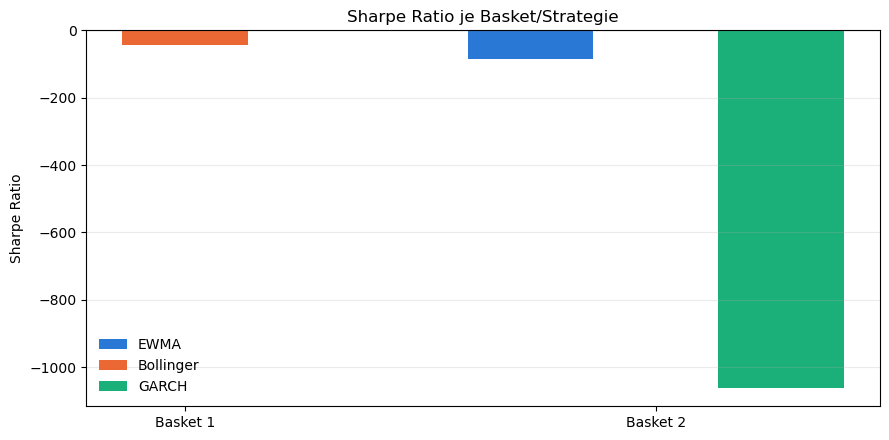

In [9]:
if not stats_df.empty:
    plot_metric_bars(stats_df, "sharpe", ylabel="Sharpe Ratio")

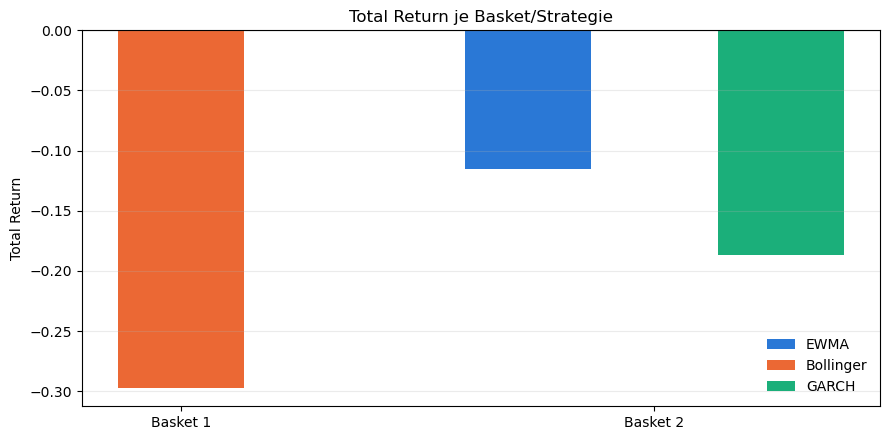

In [10]:
if not stats_df.empty:
    plot_metric_bars(stats_df, "total_return", ylabel="Total Return")

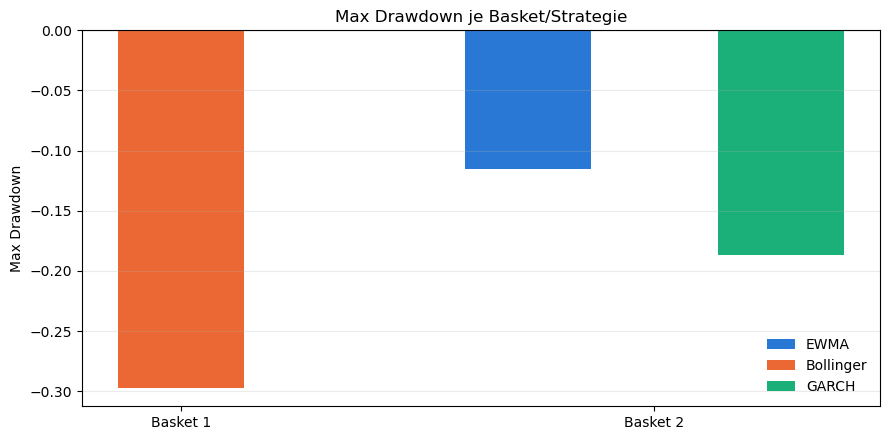

In [11]:
if not stats_df.empty:
    plot_metric_bars(stats_df, "max_drawdown", ylabel="Max Drawdown")

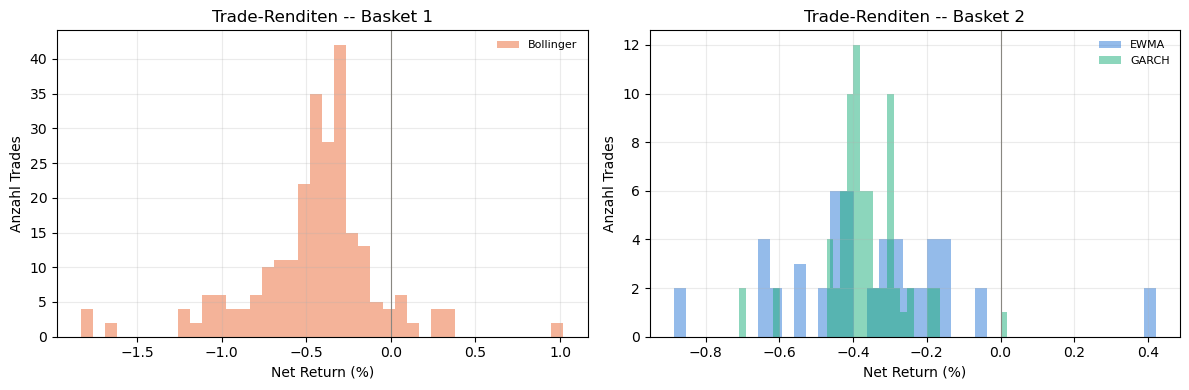

In [12]:
if results:
    plot_trade_return_distributions(results)

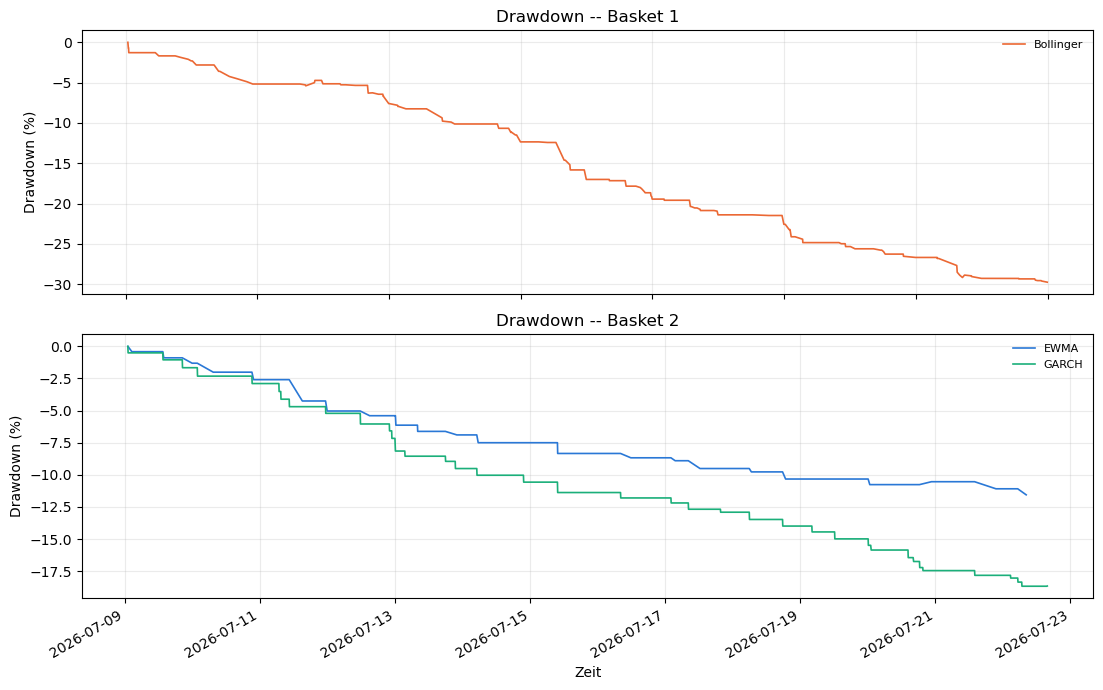

In [13]:
if results:
    plot_drawdown_curves(results)

## 8. Bestes Setup je Basket (nach Sharpe)

In [14]:
if not stats_df.empty:
    best_by_basket = stats_df.loc[stats_df.groupby("basket")["sharpe"].idxmax()]
    display(best_by_basket[["basket", "strategy", "sharpe", "total_return", "win_rate", "max_drawdown", "n_trades"]])

,basket,strategy,sharpe,total_return,win_rate,max_drawdown,n_trades
0,Basket 1,Bollinger,-42.626430,-0.297583,0.071429,-0.297583,252
1,Basket 2,EWMA,-84.479281,-0.115554,0.039216,-0.115554,51


## Wie werden die Signale berechnet? 

Alle drei Strategien handeln **Paare** von Assets innerhalb einer TDA-Clique
(z.B. BTC/ETH) und wetten darauf, dass sich der **Preis-Spread** zwischen
den beiden wieder annaehert ("Mean Reversion"), sobald er zu weit
auseinanderlaeuft. Der Preis-Spread ist:

```
spread_t = log(Preis_A) - hedge_ratio * log(Preis_B)
```

Die `hedge_ratio` (per Regression geschaetzt) sorgt dafuer, dass der Spread
selbst normalerweise um einen stabilen Mittelwert schwankt. Die drei
Strategien unterscheiden sich darin, **wie** sie messen, ob der Spread
gerade "zu weit weg" ist, und **wann** sie wieder aussteigen.

### EWMA-Toleranzintervall (nach Lin, Chen & Syu 2021)

1. **Rendite-Differenz statt Preis-Spread fuer den Entry:** `R_t = r_A - r_B`
   (die Differenz der Kerzen-Renditen der beiden Assets).
2. **Vola-Normierung:** `R_t` wird durch seine eigene, gleitend geschaetzte
   Volatilitaet geteilt (EWMA -- exponentiell gewichteter gleitender
   Durchschnitt, reagiert schneller auf aktuelle Marktlage als ein simpler
   Durchschnitt): `X_t = R_t / sigma_t`. Ergebnis: ein vola-bereinigter
   Wert, der ueber die Zeit vergleichbar ist (in "wie viele Standard-
   abweichungen ist das ungewoehnlich" gemessen).
3. **Ueber alle Paare der Clique maximieren:** `Xmax_t = max(|X_t|)` -- das
   Paar mit dem aktuell extremsten Wert wird zum Handelskandidaten.
4. **Statistische Grenze (Wilks-Toleranzintervall):** aus der juengsten
   Historie von `Xmax` wird ein Wertebereich geschaetzt, der z.B. 95% aller
   bisherigen Werte abdeckt. Ueberschreitet `Xmax_t` diese Grenze -> **Entry**.
5. **Exit:** unabhaengig vom Entry-Signal -- der Trade schliesst, sobald der
   tatsaechliche **Preis-Spread** (nicht die Rendite-Differenz!) seinen
   eigenen rollierenden Mittelwert wieder erreicht ("zurueck zur Mitte").

### Bollinger-Baender (klassischer Ansatz)

1. Arbeitet direkt auf dem **Preis-Spread** (kein Umweg ueber Renditen).
2. Gleitender Mittelwert + gleitende Standardabweichung des Preis-Spreads
   ueber ein Lookback-Fenster ergeben die Baender:
   `oberes Band = Mittelwert + n_std * Std`, analog das untere Band.
3. `Z_t = (spread_t - Mittelwert_t) / Std_t` -- wie weit (in Standard-
   abweichungen) der aktuelle Spread vom Band-Zentrum entfernt ist.
4. Ueber alle Paare der Clique: `Zmax_t = max(|Z_t|)`. Durchbricht der
   Spread eines Paares sein eigenes Band (`|Z_t| > n_std`) -> **Entry**.
5. **Exit:** wie bei EWMA -- sobald der Preis-Spread seinen eigenen
   (separaten) rollierenden Mittelwert wieder erreicht.

### GARCH-Toleranzintervall (Variante von EWMA)

Gleicher Ablauf wie EWMA (Schritte 1, 3, 4 identisch: Rendite-Differenz,
Xmax ueber alle Paare, Wilks-Toleranzgrenze fuer den Entry), aber:

- **Vola-Schaetzung:** statt EWMA (fester Glaettungsfaktor) wird pro Paar
  ein **GARCH(1,1)-Modell** an die Renditen gefittet -- ein statistisches
  Modell, das "ruhige" und "unruhige" Marktphasen selbststaendig erkennt und
  die Volatilitaet entsprechend anpasst (in turbulenten Phasen reagiert es
  staerker als ein simpler gleitender Durchschnitt). Wird **pro Clique-Tag
  neu gefittet**, deshalb ist GARCH klar rechenintensiver als EWMA.
- **Exit:** anders als bei EWMA/Bollinger NICHT auf dem Preis-Spread,
  sondern auf demselben vola-normierten `|X_t|` wie beim Entry -- der Trade
  schliesst, sobald `|X_t|` die **Mitte** zwischen unterer und oberer
  Toleranzgrenze wieder erreicht. Der Preis-Spread-Plot unten zeigt den
  Preis-Spread deshalb **ohne** Exit-Referenzlinie (es gibt keine sinnvolle
  Linie auf DIESER Skala) -- die Exit-Marker sitzen trotzdem an der
  richtigen Stelle, nur die Entscheidung dahinter basiert auf einer anderen
  Groesse.

**Kurz gesagt:** EWMA und GARCH fragen "wie ungewoehnlich bewegt sich Asset A
gerade relativ zu Asset B, verglichen mit der jeweils eigenen (aktuellen)
Volatilitaet?", waehrend Bollinger direkter fragt "wie weit ist der
Preis-Spread selbst von seinem eigenen Durchschnitt entfernt?".

## 9. Spread/Signal-Plots (Xmax bzw. Zmax mit Entry-Grenzen und Entry-Markern)

Reproduziert je (Strategie, Basket) die bestehenden Diagnose-Plots aus den
drei Engine-Modulen (`pairtrading_engine.plot_xmax_with_tolerance_bands`,
`bollinger_pairtrading_engine.plot_spread_with_bollinger_bands`,
`garch_pairtrading_engine.plot_xmax_with_garch_bands`) fuer EINEN
Discovery-Tag -- den mit den MEISTEN Trades im Testzeitraum, damit
garantiert Entry-Marker sichtbar sind. Zeigt die aggregierte Signalgroesse
der Clique (max |Z| bzw. max |X| ueber alle Paare) plus die Entry-Grenzen
und die tatsaechlich ausgeloesten Entry-Punkte -- WANN/WARUM ein Trade
ausgeloest wurde, nicht den Preis-Spread-Verlauf eines einzelnen Paares.

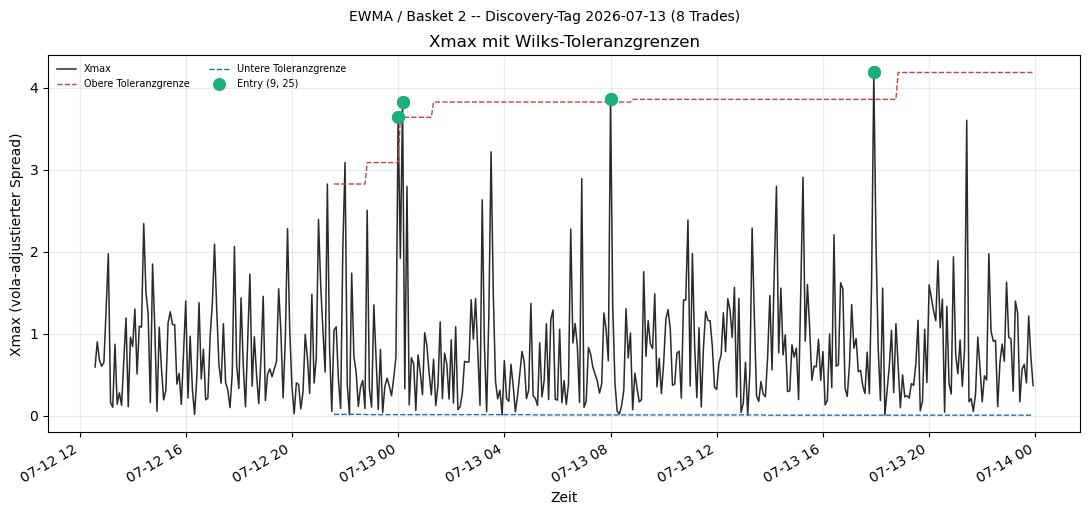

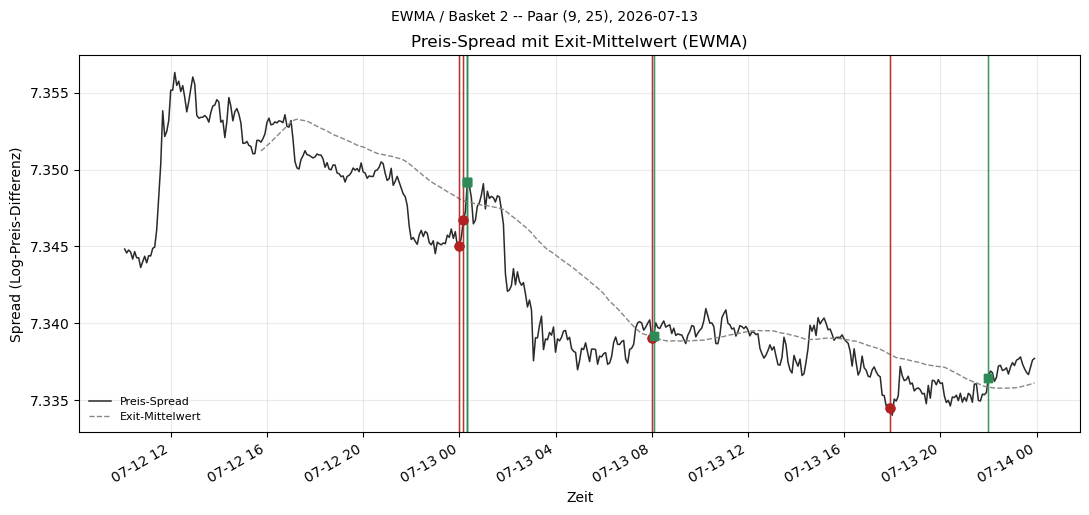

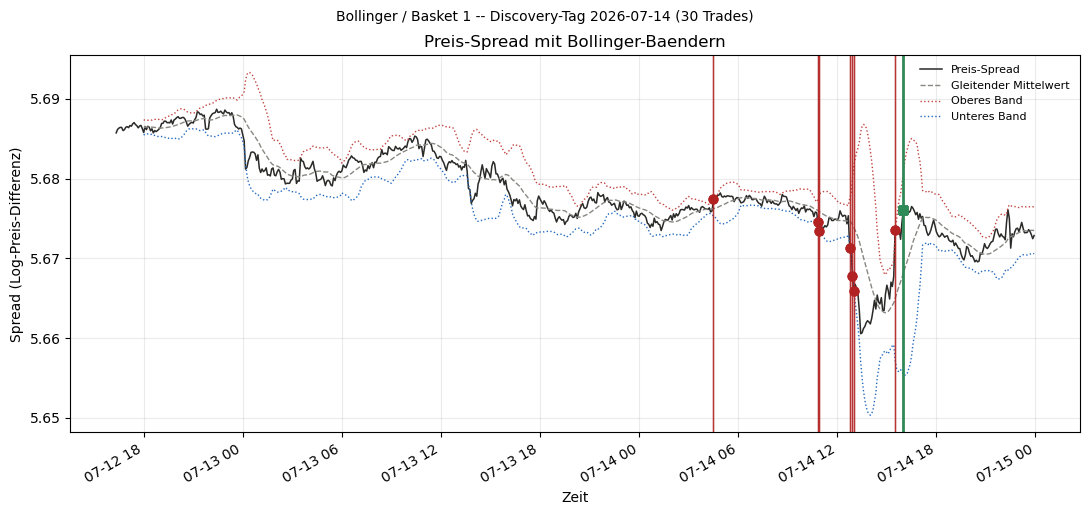

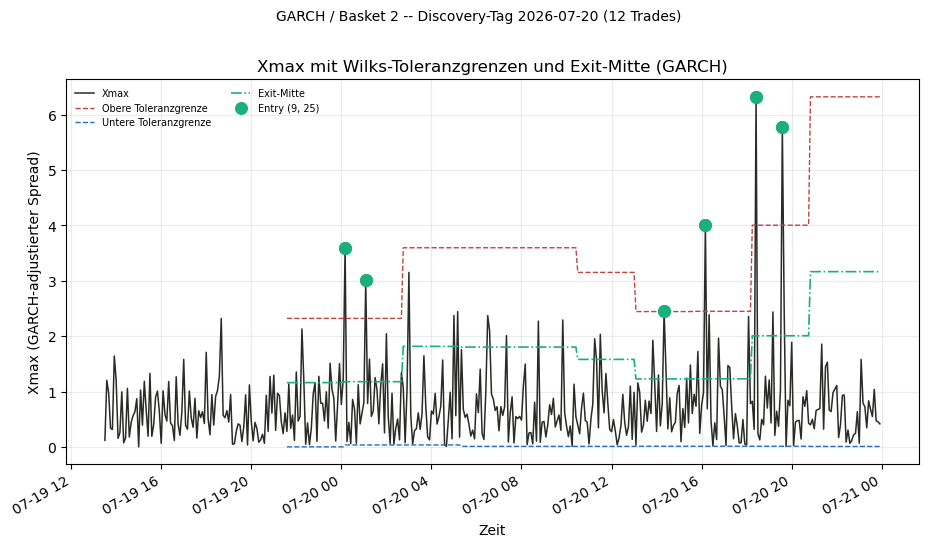

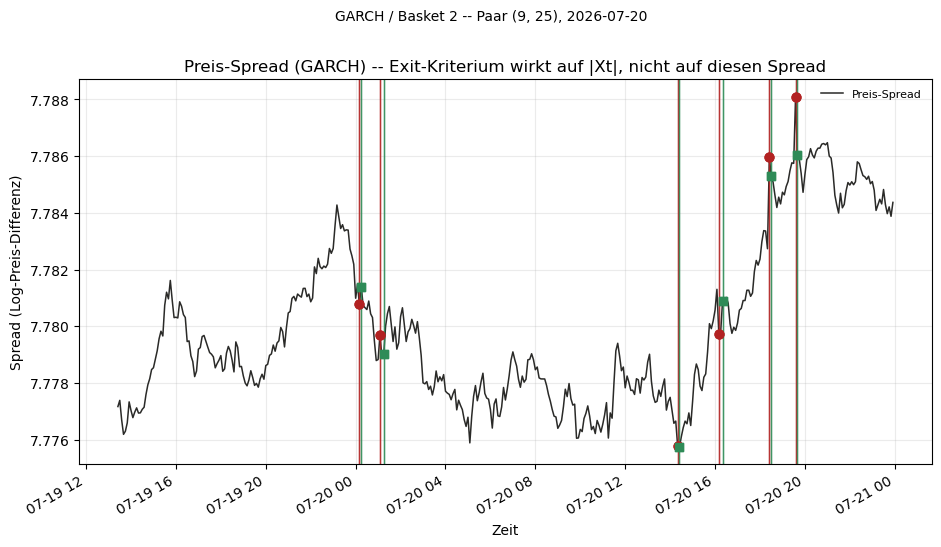

In [15]:
def _busiest_discovery_day(trades_df: pd.DataFrame):
    """Discovery-Tag (Clique) mit den meisten Trades in trades_df, oder
    None falls trades_df leer ist."""
    if trades_df.empty:
        return None
    return trades_df["discovery_date"].value_counts().idxmax()


def _clique_window(basket: str, discovery_date: pd.Timestamp, *, warmup_candles: int):
    """Baut price_matrix/window_prices/day_start fuer EINEN Discovery-Tag --
    dieselbe Fenster-Logik wie in run_*_backtest (siehe dortige Docstrings),
    hier isoliert fuer den Plot statt fuer die volle Trade-Simulation."""
    price_matrix = ohlcv_df.pivot_table(
        index=TIMESTAMP_COL, columns=ASSET_ID_COL, values=CLOSE_COL, aggfunc="last",
    ).sort_index()
    ts_index = price_matrix.index

    day_start = pd.Timestamp(discovery_date).normalize()
    day_end = day_start + pd.Timedelta(days=1)
    day_start_pos = ts_index.searchsorted(day_start)
    day_end_pos = ts_index.searchsorted(day_end)
    window_start_pos = max(0, day_start_pos - warmup_candles)

    clique_row = cliques_df_full.loc[
        (cliques_df_full["basket"] == basket) & (cliques_df_full["discovery_date"] == discovery_date)
    ].iloc[0]
    clique_ids = [a for a in clique_row.asset_ids if a in price_matrix.columns]

    window_prices = price_matrix.iloc[window_start_pos:day_end_pos][clique_ids]
    return window_prices, day_start


def plot_signal_for_strategy(strategy_name: str, basket: str, params: dict, trades_df: pd.DataFrame):
    """Waehlt den Discovery-Tag mit den meisten Trades und plottet:
      - die aggregierte Signalgroesse der Clique (Xmax/Zmax) mit Entry-
        Grenzen und Entry-Markern (bestehende plot_xmax_*/plot_spread_*-
        Funktionen der Engines), UND
      - fuer EWMA/GARCH zusaetzlich den Preis-Level-Spread DES
        meistgehandelten Paares an diesem Tag mit Entry-/Exit-Markern
        (plot_price_spread_with_exit/plot_price_spread) -- bei Bollinger
        ist das bereits derselbe Plot wie oben (dort ist die Signalgroesse
        selbst schon der Preis-Spread eines Paares)."""
    discovery_date = _busiest_discovery_day(trades_df)
    if discovery_date is None:
        print(f"{strategy_name} / {basket}: keine Trades -- kein Signal-Plot moeglich.")
        return None

    day_trades = trades_df.loc[trades_df["discovery_date"] == discovery_date]

    if strategy_name == "EWMA":
        warmup_candles = max(params["lookback_candles"], params["exit_lookback_candles"]) + 30
        window_prices, day_start = _clique_window(basket, discovery_date, warmup_candles=warmup_candles)
        spread_df = pte.build_pairwise_return_spreads(window_prices)
        adjusted_df = pte.compute_adjusted_spreads(spread_df, decay=params["ewma_decay"])
        max_spread_df = pte.compute_max_adjusted_spread(adjusted_df)
        tolerance_df = pte.generate_tolerance_signals(
            max_spread_df, lookback_candles=params["lookback_candles"],
            p_content=params["p_content"], confidence=tc.FIXED_CONFIDENCE,
            recalib_every=params["recalib_every"],
        )
        ax = pte.plot_xmax_with_tolerance_bands(max_spread_df, tolerance_df, day_trades, show=False)
        ax.figure.suptitle(f"{strategy_name} / {basket} -- Discovery-Tag {day_start.date()} "
                            f"({len(day_trades)} Trades)", fontsize=10, y=1.02)
        plt.show()

        # Zusaetzlich: Preis-Level-Spread des meistgehandelten Paares + Exit-Mittelwert.
        busiest_pair = day_trades["pair"].value_counts().idxmax()
        price_spread_df, _hedge_ratios = pte.build_pairwise_price_spreads(
            window_prices, hedge_lookback_candles=params["exit_lookback_candles"],
        )
        exit_mean_df = pte.compute_exit_mean(price_spread_df, exit_lookback_candles=params["exit_lookback_candles"])
        pair_trades = day_trades.loc[day_trades["pair"] == busiest_pair]
        ax2 = pte.plot_price_spread_with_exit(
            price_spread_df[busiest_pair], exit_mean_df[busiest_pair], pair_trades, show=False,
        )
        ax2.figure.suptitle(f"{strategy_name} / {basket} -- Paar {busiest_pair}, {day_start.date()}",
                             fontsize=10, y=1.02)
        plt.show()
        return ax2

    elif strategy_name == "Bollinger":
        warmup_candles = max(params["lookback_candles"], params["exit_lookback_candles"]) + 30
        window_prices, day_start = _clique_window(basket, discovery_date, warmup_candles=warmup_candles)
        spread_df, _hedge_ratios = bpe.build_pairwise_price_spreads(
            window_prices, hedge_lookback_candles=params["hedge_lookback_candles"],
        )
        bands = bpe.compute_bollinger_bands(spread_df, lookback_candles=params["lookback_candles"], n_std=params["n_std"])
        # Paar mit den meisten Trades an diesem Tag -- band_df ist pro Paar, nicht pro Clique.
        busiest_pair = day_trades["pair"].value_counts().idxmax()
        pair_trades = day_trades.loc[day_trades["pair"] == busiest_pair]
        ax = bpe.plot_spread_with_bollinger_bands(bands[busiest_pair], pair_trades, show=False)
        ax.figure.suptitle(f"{strategy_name} / {basket} -- Discovery-Tag {day_start.date()} "
                            f"({len(day_trades)} Trades)", fontsize=10, y=1.02)
        plt.show()
        return ax

    elif strategy_name == "GARCH":
        warmup_candles = params["lookback_candles"] + 30
        window_prices, day_start = _clique_window(basket, discovery_date, warmup_candles=warmup_candles)
        spread_df = ge.build_pairwise_return_spreads(window_prices)
        adjusted_df, _fit_info = ge.compute_garch_adjusted_spreads(spread_df)
        max_spread_df = ge.compute_max_adjusted_spread(adjusted_df)
        tolerance_df = ge.generate_tolerance_signals(
            max_spread_df, lookback_candles=params["lookback_candles"],
            p_content=params["p_content"], confidence=tc.FIXED_CONFIDENCE,
            recalib_every=params["recalib_every"],
        )
        ax = ge.plot_xmax_with_garch_bands(max_spread_df, tolerance_df, day_trades, show=False)
        ax.figure.suptitle(f"{strategy_name} / {basket} -- Discovery-Tag {day_start.date()} "
                            f"({len(day_trades)} Trades)", fontsize=10, y=1.02)
        plt.show()

        # Zusaetzlich: Preis-Level-Spread des meistgehandelten Paares (ohne
        # Referenzlinie -- der GARCH-Exit wirkt auf |Xt|, nicht auf diesen
        # Preis-Spread, siehe plot_price_spread-Docstring).
        busiest_pair = day_trades["pair"].value_counts().idxmax()
        price_spread_df, _hedge_ratios = bpe.build_pairwise_price_spreads(window_prices)
        pair_trades = day_trades.loc[day_trades["pair"] == busiest_pair]
        ax2 = ge.plot_price_spread(price_spread_df[busiest_pair], pair_trades, show=False)
        ax2.figure.suptitle(f"{strategy_name} / {basket} -- Paar {busiest_pair}, {day_start.date()}",
                             fontsize=10, y=1.02)
        plt.show()
        return ax2

    else:
        raise ValueError(f"Unbekannte Strategie: {strategy_name}")


for (strat_name, basket), res in results.items():
    params = best_params_by_strategy[strat_name][basket]
    plot_signal_for_strategy(strat_name, basket, params, res["trades_df"])